# Workshop 00 — How to know your model got better

**The situation.** You changed something in your notebook. The number moved. Did your model
improve, or did you just get lucky?

Last week you built a housing-price baseline, tried a few scalers, removed some outliers. The
numbers moved around. Today we make that process **trustworthy**, so that when you tell someone
"removing outliers gained me 0.3 RMSE", it is a fact and not a coincidence.

Three ideas, and that is the whole workshop:

1. **Three sets, three questions** — train, validation, test.
2. **One change at a time** — the only way to know *what* caused a gain.
3. **A logbook** — because you will not remember what run 14 did.

By the end you will have run a small experiment campaign and defended a decision with numbers.

In [ ]:
# ABOUTME: Workshop 00 - experimental methodology for model training.
# ABOUTME: Train/validation/test, leakage, one change at a time, and the experiment logbook.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler
from sklearn.metrics import mean_squared_error

SEED = 42          # Rule number zero: the seed is part of the experiment. Write it down.
rng = np.random.default_rng(SEED)
pd.set_option("display.width", 120)

## A dataset we understand completely

Real data hides its own answer. For one workshop we use a *simulated* housing market, so we know
the true relationship and can check whether our method finds it.

Each house has: `rooms`, `income` of the area, `age` of the building, and `distance` to the centre.
The price is built from those with a rule we fix ourselves, plus noise. We also sprinkle in a few
**bad records** — the kind of sensor glitch or typo every real dataset has.

In [ ]:
def make_housing(n=1200, seed=SEED):
    """A small housing market with a known price rule, plus 2% corrupted records."""
    rng = np.random.default_rng(seed)
    rooms = rng.normal(5.5, 1.2, n).clip(1, 10)
    income = rng.normal(5.0, 1.8, n).clip(0.5, 15)
    age = rng.integers(0, 90, n).astype(float)
    distance = rng.exponential(3.0, n).clip(0.2, 25)

    # The truth we are trying to recover: income and rooms push the price up, distance and age down.
    price = 8 * income + 12 * rooms - 1.2 * distance - 0.05 * age + rng.normal(0, 6, n)

    df = pd.DataFrame({"rooms": rooms, "income": income, "age": age,
                       "distance": distance, "price": price})
    # 2% of rows are broken: a stuck sensor reporting an absurd number of rooms.
    broken = rng.choice(n, size=int(0.02 * n), replace=False)
    df.loc[broken, "rooms"] = rng.uniform(40, 90, len(broken))
    return df

housing = make_housing()
print(housing.shape)
housing.head()

(1200, 5)


,rooms,income,age,distance,price
0,5.865660,2.619426,31.0,5.868754,87.682452
1,4.252019,4.124851,59.0,0.578822,83.836182
2,6.400541,5.756408,55.0,2.672767,110.880537
3,6.628678,4.815686,64.0,4.102018,117.612379
4,3.158758,3.828985,17.0,2.680953,59.411038


## 1. Three sets, three questions

One dataset, split three ways, because you are asking three *different* questions:

| set | share | the question it answers | how often you may look |
|---|---|---|---|
| **train** | 70 % | What should the model's parameters be? | constantly — the model reads it |
| **validation** | 15 % | Which of my ideas is best? | every experiment |
| **test** | 15 % | How well will this do on data nobody has seen? | **once**, at the very end |

The test set is not a third opinion. It is a one-shot measurement, and every time you peek at it
and then change something, you spend a little of its honesty.

**Rule of thumb:** if a number influenced a decision you made, it cannot also be your final
estimate of quality.

In [ ]:
def split(df, seed=SEED):
    """70/15/15, shuffled once with a fixed seed so every experiment sees the same three sets."""
    shuffled = df.sample(frac=1.0, random_state=seed).reset_index(drop=True)
    n_train, n_val = int(0.70 * len(df)), int(0.85 * len(df))
    return shuffled[:n_train], shuffled[n_train:n_val], shuffled[n_val:]

train, val, test = split(housing)
print(f"train {len(train)}  val {len(val)}  test {len(test)}")

FEATURES, TARGET = ["rooms", "income", "age", "distance"], "price"

def rmse(model, data):
    """One metric, chosen up front, in the units of the target. Lower is better."""
    pred = model.predict(data[FEATURES])
    return float(np.sqrt(mean_squared_error(data[TARGET], pred)))

baseline = LinearRegression().fit(train[FEATURES], train[TARGET])
print(f"baseline RMSE  train {rmse(baseline, train):.3f} | val {rmse(baseline, val):.3f}")
print(f"target std (the 'predict the mean' bar): {train[TARGET].std():.3f}")

train 840  val 180  test 180
baseline RMSE  train 15.490 | val 15.085
target std (the 'predict the mean' bar): 21.639


**The punchline:** a model is only "good" next to something. A validation RMSE of 15 means little
until you know that predicting the average scores ~22. Always compute the dumb baseline.

And 15 against 22 is a *poor* model for data built from a clean linear rule. Something is wrong.

## 2. Look at your errors before you tune anything

The fastest way to find out what is wrong: ask the model where it fails hardest.

In [ ]:
val_errors = val.assign(predicted=baseline.predict(val[FEATURES]))
val_errors["error"] = (val_errors.predicted - val_errors.price).abs()
val_errors.nlargest(5, "error")[["rooms", "income", "price", "predicted", "error"]].round(2)

,rooms,income,price,predicted,error
921,2.42,5.42,58.72,104.72,46.00
853,8.87,8.40,174.34,130.62,43.73
940,73.11,9.10,104.97,146.46,41.49
879,2.50,3.87,51.88,90.50,38.62
959,8.52,6.48,154.27,116.41,37.86


There it is: houses with **40 to 90 rooms**. Not mansions — a broken sensor. Those records poison
the fit for every other row, and they are 2 % of the data.

This is a **data validation** problem, not a modelling one. A house has at most ~15 rooms; anything
above that is an invalid reading. And invalid readings do not disappear when you deploy, so the fix
belongs in the pipeline and applies to **every** set you will ever score: train, validation, test,
and tomorrow's production rows.

In [ ]:
MAX_ROOMS = 15

def clean_rooms(df, replacement):
    """Repair impossible room counts. A validation rule: it applies to every set, always."""
    out = df.copy()
    out.loc[out.rooms > MAX_ROOMS, "rooms"] = replacement
    return out

# The replacement value is a statistic, so it is learned from TRAINING data only.
median_rooms = train.loc[train.rooms <= MAX_ROOMS, "rooms"].median()
clean_train, clean_val = clean_rooms(train, median_rooms), clean_rooms(val, median_rooms)

cleaned = LinearRegression().fit(clean_train[FEATURES], clean_train[TARGET])
print(f"baseline RMSE on val : {rmse(baseline, val):.3f}")
print(f"cleaned  RMSE on val : {rmse(cleaned, clean_val):.3f}   <- same model, repaired data")

baseline RMSE on val : 15.085
cleaned  RMSE on val : 6.176   <- same model, repaired data


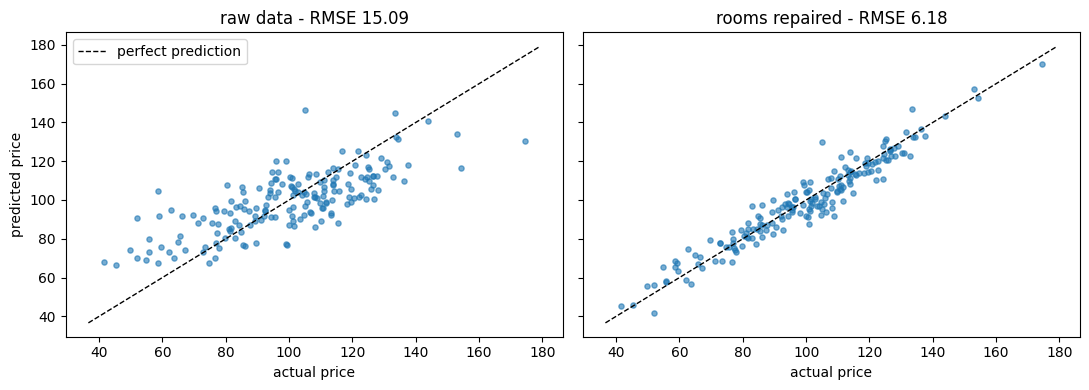

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
for ax, (model, data, title) in zip(axes, [(baseline, val, "raw data"), (cleaned, clean_val, "rooms repaired")]):
    ax.scatter(data[TARGET], model.predict(data[FEATURES]), s=14, alpha=0.6)
    lims = [data[TARGET].min() - 5, data[TARGET].max() + 5]
    ax.plot(lims, lims, "k--", lw=1, label="perfect prediction")
    ax.set_xlabel("actual price"); ax.set_title(f"{title} - RMSE {np.sqrt(mean_squared_error(data[TARGET], model.predict(data[FEATURES]))):.2f}")
axes[0].set_ylabel("predicted price"); axes[0].legend()
plt.tight_layout()

Same model, same split, same metric — the only difference is 2 % of repaired rows. On the left the
cloud is wide and tilted; on the right it hugs the diagonal.

**Rule of thumb:** before you reach for a fancier model, look at your five worst predictions. Data
quality beats model choice almost every time, and it is cheaper.

## 3. The leak

Now the mistake that quietly inflates results. There are two flavours, and one is far worse than
the other.

**Flavour A — a statistic computed on everything.** We needed a median to repair the rooms. Compute
it over the whole dataset and your training pipeline has been told something about validation rows.

**Flavour B — cleaning the exam paper.** The broken rows are annoying, so you drop them from
validation as well. Your score improves beautifully. It is also a lie: production will keep sending
broken rows, and your model will keep meeting them.

In [ ]:
# Flavour A: the repair statistic learned from all the data instead of the training set.
leaky_median = housing.loc[housing.rooms <= MAX_ROOMS, "rooms"].median()
leaky_a = LinearRegression().fit(clean_rooms(train, leaky_median)[FEATURES], train[TARGET])
rmse_a = rmse(leaky_a, clean_rooms(val, leaky_median))

# Flavour B: the broken validation rows simply deleted, so nothing scores against them.
honest_val = clean_val
flattered_val = val[val.rooms <= MAX_ROOMS]
rmse_b = rmse(cleaned, flattered_val)

print(f"honest        : {rmse(cleaned, honest_val):.3f}")
print(f"leak flavour A: {rmse_a:.3f}   (median from all rows: a small, silent bias)")
print(f"leak flavour B: {rmse_b:.3f}   (broken rows deleted from validation: a different question)")

honest        : 6.176
leak flavour A: 6.178   (median from all rows: a small, silent bias)
leak flavour B: 5.700   (broken rows deleted from validation: a different question)


Flavour A moves the score by a hair. That is precisely what makes leakage dangerous: it rarely
announces itself, it just makes validation a little too kind, and you discover the truth in
production.

Flavour B looks like the best result of the day. It is simply the answer to a different question —
"how good is my model on the rows I like?" — and nobody deploys into that world.

The habit that protects you from both costs nothing: **split first; let every statistic learn from
training rows only; never remove rows from validation that production will keep sending you.**

### Exercise 1 — spot the leak

Three snippets. Which ones leak information from validation into training? Return the list of
numbers that are **leaky**.

1. `scaler = StandardScaler().fit(df[FEATURES]); train, val, test = split(df)`
2. `train, val, test = split(df); imputer_value = train["age"].median(); val["age"] = val["age"].fillna(imputer_value)`
3. `df["price_rank"] = df["price"].rank(pct=True); train, val, test = split(df)`

In [ ]:
def leaky_snippets():
    """Return a sorted list of the snippet numbers that leak. Example: [1, 2]"""
    # 1 leaks: the scaler's mean/std are computed over rows that later become val and test.
    # 2 is honest: the median comes from train only, and is then APPLIED to val. That is correct.
    # 3 leaks: a percentile rank of the TARGET over the whole dataset encodes every row's
    #   position relative to the others - including the ones we pretend not to have seen.
    return [1, 3]

print("your answer:", leaky_snippets())

your answer: [1, 3]


In [ ]:
def check(label, *conditions):
    """Report an exercise self-check without raising: a red traceback is a bad first impression."""
    try:
        ok = all(bool(c()) for c in conditions)
    except Exception as exc:                      # a stub that still returns None lands here
        print(f"  {label}: not yet ({type(exc).__name__}: {exc})")
        return False
    print(f"  {label}: {'PASS' if ok else 'not yet'}")
    return ok

check("Exercise 1", lambda: leaky_snippets() == [1, 3])

  Exercise 1: PASS


True

## 3. One change at a time

You have two ideas: remove the broken rows, and scale the features. You try both at once, the
score improves, and you have learned... that *something* helped. If the next dataset behaves
differently you will not know which half to keep.

So: **one change per run, everything else frozen.** Four runs instead of one, and real knowledge
at the end.

A run is a configuration and a result:

```
run | change                 | val RMSE | kept?
  0 | baseline               |   ...    |  -
  1 | + outlier removal      |   ...    |  ?
  2 | + robust scaler        |   ...    |  ?
  3 | + both                 |   ...    |  ?
```

### Exercise 2 — the experiment function

Write `run_experiment`, the thing you will reuse for the rest of the project. It must:

- work on **copies**, never mutating the caller's data,
- apply the rooms repair to **both** sets when asked (it is a pipeline rule, not a model choice),
  using a median computed from the training set only,
- fit the scaler on training rows only,
- return the validation RMSE.

In [ ]:
def run_experiment(tr, va, clean=False, scaler=None, model=None):
    """Fit one configuration and return its validation RMSE.

    tr, va : training and validation DataFrames
    clean  : repair rooms > MAX_ROOMS in BOTH sets, using the training median
    scaler : an unfitted sklearn scaler, or None
    model  : an unfitted sklearn regressor; defaults to LinearRegression()
    """
    tr, va = tr.copy(), va.copy()
    # `model or LinearRegression()` would call bool() on an unfitted forest, which raises. Use `is None`.
    model = LinearRegression() if model is None else model
    if clean:
        replacement = tr.loc[tr.rooms <= MAX_ROOMS, "rooms"].median()   # training rows only
        tr, va = clean_rooms(tr, replacement), clean_rooms(va, replacement)
    Xtr, Xva = tr[FEATURES], va[FEATURES]
    if scaler is not None:
        Xtr = scaler.fit_transform(Xtr)      # statistics from training rows only
        Xva = scaler.transform(Xva)
    model.fit(Xtr, tr[TARGET])
    return float(np.sqrt(mean_squared_error(va[TARGET], model.predict(Xva))))

print("baseline via run_experiment:", run_experiment(train, val))

baseline via run_experiment: 15.085013782867689


In [ ]:
def check(label, *conditions):
    """Report an exercise self-check without raising: a red traceback is a bad first impression."""
    try:
        ok = all(bool(c()) for c in conditions)
    except Exception as exc:                      # a stub that still returns None lands here
        print(f"  {label}: not yet ({type(exc).__name__}: {exc})")
        return False
    print(f"  {label}: {'PASS' if ok else 'not yet'}")
    return ok

base = run_experiment(train, val)
check("returns a float", lambda: isinstance(base, float))
check("matches the baseline above", lambda: abs(base - rmse(baseline, val)) < 1e-9)
check("cleaning improves the score", lambda: run_experiment(train, val, clean=True) < base)
check("caller's data untouched", lambda: train.rooms.max() > MAX_ROOMS)

  returns a float: PASS
  matches the baseline above: PASS
  cleaning improves the score: PASS
  caller's data untouched: PASS


True

### Exercise 3 — run the campaign and decide

Fill the logbook below: four runs, one change each, same seed, same metric. Then answer in one
sentence: **which changes do you keep, and why?**

In [ ]:
runs = [
    dict(name="0 baseline",      clean=False, scaler=None,           model=None),
    dict(name="1 clean rooms",   clean=True,  scaler=None,           model=None),
    dict(name="2 robust scaler", clean=False, scaler=RobustScaler(), model=None),
    dict(name="3 random forest", clean=False, scaler=None,           model=RandomForestRegressor(random_state=SEED)),
]

rows = []
for cfg in runs:
    cfg = dict(cfg)                      # never mutate the config you are logging
    name = cfg.pop("name")
    rows.append({"run": name, "val_rmse": round(run_experiment(train, val, **cfg), 4)})
logbook = pd.DataFrame(rows)
logbook["delta_vs_baseline"] = (logbook.val_rmse - logbook.val_rmse[0]).round(4)
logbook

,run,val_rmse,delta_vs_baseline
0,0 baseline,15.0850,0.0000
1,1 clean rooms,6.1762,-8.9088
2,2 robust scaler,15.0850,0.0000
3,3 random forest,7.7453,-7.3397


Read your table before scrolling on. Three different kinds of result:

- **Repairing the rooms is the whole game.** One validation rule beats any amount of model tuning,
  because it removes the thing that was actually breaking the fit.
- **The scaler changes nothing at all** — to the fourth decimal. Ordinary least squares has a
  closed-form solution that is invariant to feature scaling. It is not a useless technique; it is
  useless *here*. It starts to matter the moment you fit with gradient descent (workshop LR-03) or
  use a model with a distance or a penalty in it.
- **The random forest improves on the broken data** without being told the rule: it can isolate the
  absurd rows in their own branches. A stronger model can paper over a data problem — which is
  exactly why you should fix the data first and then ask whether you still need the stronger model.

**Rule of thumb:** when a change makes no difference, that is a result worth writing down. It stops
you from trying it again in three weeks.

### Exercise 4 — the final measurement

You have made your decisions on validation. Now, exactly once: take the configuration with the best
validation score, retrain it on **train + validation together** (more data, same recipe), and
measure it on the test set.

In [ ]:
winner_row = logbook.loc[logbook.val_rmse.idxmin()]
winner = next(dict(c) for c in runs if c["name"] == winner_row.run)
winner.pop("name")

full_train = pd.concat([train, val], ignore_index=True)
test_rmse = run_experiment(full_train, test, **winner)

print(f"winner:               {winner_row.run}")
print(f"winner on validation: {winner_row.val_rmse:.4f}")
print(f"winner on test:       {test_rmse:.4f}")
print(f"difference:           {test_rmse - winner_row.val_rmse:+.4f}")

winner:               1 clean rooms
winner on validation: 6.1762
winner on test:       5.8536
difference:           -0.3226


In [ ]:
def check(label, *conditions):
    """Report an exercise self-check without raising: a red traceback is a bad first impression."""
    try:
        ok = all(bool(c()) for c in conditions)
    except Exception as exc:                      # a stub that still returns None lands here
        print(f"  {label}: not yet ({type(exc).__name__}: {exc})")
        return False
    print(f"  {label}: {'PASS' if ok else 'not yet'}")
    return ok

check("Exercise 4", lambda: isinstance(test_rmse, float), lambda: test_rmse > 0)

  Exercise 4: PASS


True

Compare the two numbers. On this run the test score comes out slightly *better* than validation —
with 180 rows in each set, a few tenths of RMSE is noise, and noise goes both ways.

What you should expect **on average** is the opposite: test a little worse than validation. That is
not a bug, it is the price of having *chosen* your configuration using the validation score. The
more configurations you compare, the more of that optimism you accumulate — which is exactly why
the test set is spent once, at the end, and never used to pick anything.

## The logbook you actually keep

A row per run, written **as you go**, not reconstructed from memory afterwards:

| field | why it is there |
|---|---|
| date, run id | so you can find the notebook again |
| what changed | one line, one change |
| seed | without it nothing above is reproducible |
| metric + value | the single number you agreed on up front |
| decision | kept / dropped, and one sentence of why |

Keep it in a markdown file or a CSV next to the notebook. In six weeks it is the only reason you
will be able to explain your own results.

## What to take away

1. **Split first, transform after.** Every statistic — mean, median, rank, vocabulary — learns
   from training data only.
2. **One change per run.** Two changes at once teach you nothing about either.
3. **Pick the metric before you look.** Changing the metric after seeing results is how people
   fool themselves.
4. **The dumb baseline is part of the report.** "RMSE 7" is not a result; "RMSE 7 against a
   predict-the-mean bar of 22" is.
5. **The test set is a one-shot measurement.** Spend it at the end.

### Take it home
Apply the four runs above to your own project data. Bring the logbook table next session, and be
ready to defend one line of it.